# **1. Regresión lineal**

Para ello vamos a trabajar con  la data numérica del  archivo **data.csv**



In [ ]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt # data visualization
import seaborn as sns # statistical data visualization
%matplotlib inline

from sklearn.linear_model import LogisticRegression
from sklearn import  linear_model
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, auc


# **2. REGRESIÓN LOGÍSTICA**

En esta parte del taller se trabajan los temas de regresión logística como un  clasificador binario y la clasificación binaria usando SVMs.

### **REGRESIÓN LOGÍSTICA**
En esta parte del taller se trabajan los temas de regresión logística como un
Para una compañía que ofrece un producto o servicio es muy importante llegar a la mayor cantidad de gente posible mediante la publicidad por distintos medios como internet. Existen medios, como las redes sociales, en los que las empresas pagan para publicitarse mediante estos servicios, así, muchas empresas llegan a varias personas con el fin de llamar su atención.

Muchos medios como Google o Facebook realizan reportes para las personas que se publicitan, suministrando información como la cantidad de personas que vieron la publicidad, quienes se interesaron en la misma, y demás información de las personas que interactuaron con esta. Con esta información las empresas pueden trabajar en mejorar su publicidad para llegar a un público mayor o más afin con sus productos, realizando predicciones sobre que personas se interesarán en una publicidad.

Nuestro trabajo es intentar predecir si una persona se interesará en una publicidad en línea, haciendo click en ella. Para realizar las predicciones nos basaremos en la información de las personas suministrada por la plataforma mediante la cual se realiza la publicidad.

### **Los datos:**
Contamos con un conjunto de datos con información de varios posibles clientes que recibieron la publicidad, a continuación se presentan las columnas más relevantes para realizar el trabajo:
- **Daily Time Spent on Site:** tiempo que estuvo el cliente dentro de la página web (minutos)
- **Age:** edad del cliente (años)
- **Area Income:** Ingreso promedio de las personas ubicadas en la región geográfica del cliente
- **Daily Internet Usage:** Tiempo promedio de uso de internet del cliente al día (minutos)
- **Male:** Si el cliente es de sexo masculino
- **Clicked on Ad:** Si el cliente hizo click en la publicidad (1/0 para Sí/No)

---

### **Manejo de datos:**

5. Leer el archivo ```advertising.csv``` y verificar que no tenga valores nulos, mostrar su cantidad de filas y columnas, tipos de datos e imprimir los 5 primeros registros.

In [2]:
data= pd.read_csv('data/advertising.csv')
data

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Ad Topic Line,City,Male,Country,Timestamp,Clicked on Ad
0,68.95,35,61833.90,256.09,Cloned 5thgeneration orchestration,Wrightburgh,0,Tunisia,2016-03-27 00:53:11,0
1,80.23,31,68441.85,193.77,Monitored national standardization,West Jodi,1,Nauru,2016-04-04 01:39:02,0
2,69.47,26,59785.94,236.50,Organic bottom-line service-desk,Davidton,0,San Marino,2016-03-13 20:35:42,0
3,74.15,29,54806.18,245.89,Triple-buffered reciprocal time-frame,West Terrifurt,1,Italy,2016-01-10 02:31:19,0
4,68.37,35,73889.99,225.58,Robust logistical utilization,South Manuel,0,Iceland,2016-06-03 03:36:18,0
...,...,...,...,...,...,...,...,...,...,...
995,72.97,30,71384.57,208.58,Fundamental modular algorithm,Duffystad,1,Lebanon,2016-02-11 21:49:00,1
996,51.30,45,67782.17,134.42,Grass-roots cohesive monitoring,New Darlene,1,Bosnia and Herzegovina,2016-04-22 02:07:01,1
997,51.63,51,42415.72,120.37,Expanded intangible solution,South Jessica,1,Mongolia,2016-02-01 17:24:57,1
998,55.55,19,41920.79,187.95,Proactive bandwidth-monitored policy,West Steven,0,Guatemala,2016-03-24 02:35:54,0


In [3]:
data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Daily Time Spent on Site  1000 non-null   float64
 1   Age                       1000 non-null   int64  
 2   Area Income               1000 non-null   float64
 3   Daily Internet Usage      1000 non-null   float64
 4   Ad Topic Line             1000 non-null   object 
 5   City                      1000 non-null   object 
 6   Male                      1000 non-null   int64  
 7   Country                   1000 non-null   object 
 8   Timestamp                 1000 non-null   object 
 9   Clicked on Ad             1000 non-null   int64  
dtypes: float64(3), int64(3), object(4)
memory usage: 78.3+ KB


In [4]:
data.head()

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Ad Topic Line,City,Male,Country,Timestamp,Clicked on Ad
0,68.95,35,61833.90,256.09,Cloned 5thgeneration orchestration,Wrightburgh,0,Tunisia,2016-03-27 00:53:11,0
1,80.23,31,68441.85,193.77,Monitored national standardization,West Jodi,1,Nauru,2016-04-04 01:39:02,0
2,69.47,26,59785.94,236.50,Organic bottom-line service-desk,Davidton,0,San Marino,2016-03-13 20:35:42,0
3,74.15,29,54806.18,245.89,Triple-buffered reciprocal time-frame,West Terrifurt,1,Italy,2016-01-10 02:31:19,0
4,68.37,35,73889.99,225.58,Robust logistical utilization,South Manuel,0,Iceland,2016-06-03 03:36:18,0


6. Separando la información:
    2.1 Separar los datos en Input (X) y Output (y), para el Input seleccionar las columnas descritas inicialmente, no incluir ```Ad Topic Line```, ```City```, ```Country``` ni ```Timestamp```.
    2.2 Separar los datos en Train y Test, dejar 80% de datos para entrenamiento

     Daily Time Spent on Site  Age  Area Income  Daily Internet Usage  Male
423                     58.03   31     28387.42                129.33     0
157                     41.73   28     61142.33                202.18     1
670                     77.89   26     64188.50                201.54     0
256                     80.91   32     61608.23                231.42     0
965                     35.25   50     47051.02                194.44     0
..                        ...  ...          ...                   ...   ...
575                     48.86   54     53188.69                134.46     0
838                     44.13   40     33601.84                128.48     1
337                     75.32   28     59998.50                233.60     1
523                     67.94   43     68447.17                128.16     0
863                     76.64   39     66217.31                241.50     1

[800 rows x 5 columns] 423    1
157    1
670    0
256    0
965    1
      ..
575    1
8

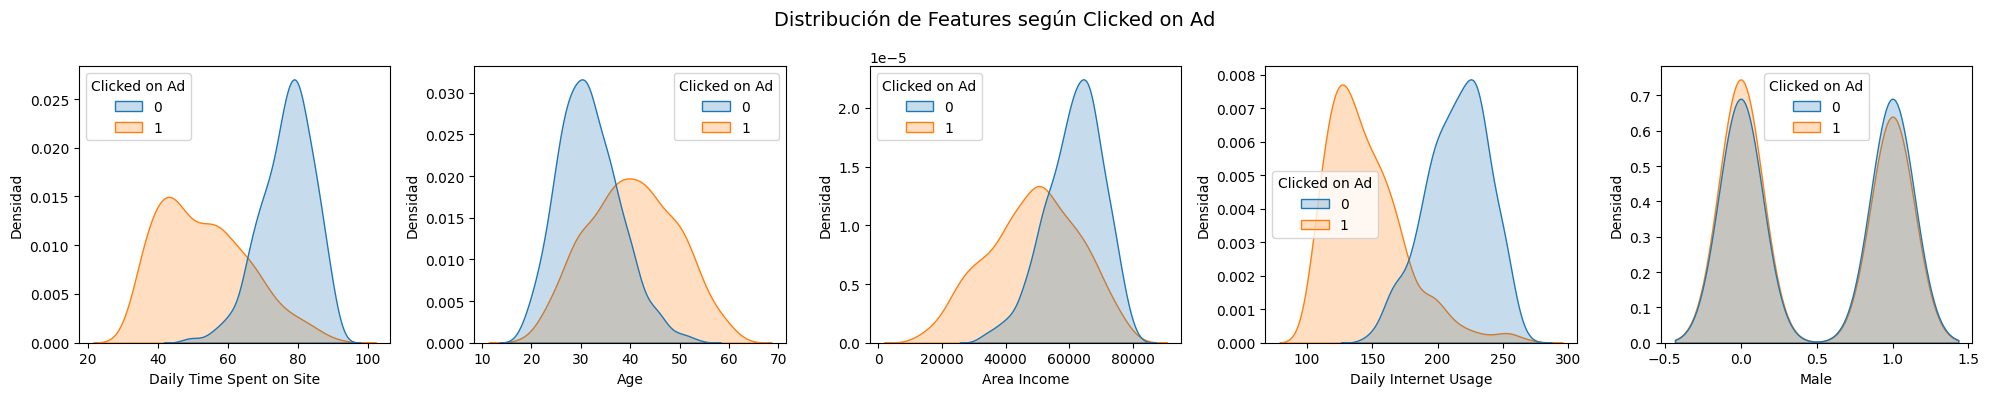

In [26]:
# Atributos relevantes
features = ['Daily Time Spent on Site', 'Age', 'Area Income', 'Daily Internet Usage', 'Male', 'Clicked on Ad']

# Separando en X y Y
X = data[features].drop('Clicked on Ad', axis=1)
y = data[features]['Clicked on Ad']


# Separando train y test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101)

print(X_train,y_train)
print(len(X_train),len(y_train))

df_plot = data[features]

#sns.pairplot(df_plot, hue='Clicked on Ad', palette='Set1', diag_kind='kde')
#plt.suptitle('Relación de todas las variables con Clicked on Ad', y=1.02)
#plt.show()

fig, axes = plt.subplots(1, len(['Daily Time Spent on Site', 'Age', 'Area Income', 'Daily Internet Usage', 'Male']), figsize=(20, 4), sharey=False)

for ax, col in zip(axes, ['Daily Time Spent on Site', 'Age', 'Area Income', 'Daily Internet Usage', 'Male']):
    sns.kdeplot(
        data=df_plot, 
        x=col, 
        hue="Clicked on Ad", 
        fill=True, 
        ax=ax,
        warn_singular=False
    )
    ax.set_xlabel(col)
    ax.set_ylabel("Densidad")

fig.suptitle("Distribución de Features según Clicked on Ad", fontsize=14)
plt.tight_layout()
plt.show()

In [6]:
print(X_test,y_test)
print(len(X_test),len(y_test))

     Daily Time Spent on Site  Age  Area Income  Daily Internet Usage  Male
545                     42.60   55     55121.65                168.29     0
298                     80.39   31     66269.49                214.74     0
109                     74.02   32     72272.90                210.54     0
837                     55.77   49     55942.04                117.33     1
194                     77.20   33     49325.48                254.05     1
..                        ...  ...          ...                   ...   ...
68                      75.74   25     61005.87                215.25     1
449                     77.69   22     48852.58                169.88     1
715                     49.19   38     61004.51                123.08     0
793                     36.62   32     51119.93                162.44     1
688                     74.58   36     70701.31                230.52     0

[200 rows x 5 columns] 545    1
298    0
109    0
837    1
194    0
      ..
68     0
4

### **Creando un modelo de regresión logística:**

7. Crear un modelo de regresión logística y entrenarlo usando  **LogisticRegresion()** . Evaluar el modelo utilizando los datos de entrenamiento

In [7]:
# Modelo de regresion logistica
log_model = LogisticRegression()
log_model.fit(X_train, y_train)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [8]:
print(X_test)
print(y_test)

     Daily Time Spent on Site  Age  Area Income  Daily Internet Usage  Male
545                     42.60   55     55121.65                168.29     0
298                     80.39   31     66269.49                214.74     0
109                     74.02   32     72272.90                210.54     0
837                     55.77   49     55942.04                117.33     1
194                     77.20   33     49325.48                254.05     1
..                        ...  ...          ...                   ...   ...
68                      75.74   25     61005.87                215.25     1
449                     77.69   22     48852.58                169.88     1
715                     49.19   38     61004.51                123.08     0
793                     36.62   32     51119.93                162.44     1
688                     74.58   36     70701.31                230.52     0

[200 rows x 5 columns]
545    1
298    0
109    0
837    1
194    0
      ..
68     0
4

In [9]:
# Predicciones
# hay que obtener el y_pred con base en el modelo  y X_test
y_pred = log_model.predict(X_test)
X_test.shape

(200, 5)

8. Crear una matriz de confusión y graficarla (se puede hacer uso de librerías como matplotlib o seaborn). ¿Cuál es la precision, recall, f1-score, el accuracy y la curva ROC?





In [10]:
# Creacion de la matriz de confusion
con_matrix = confusion_matrix(y_test, y_pred)
print('Confusion matrix\n', con_matrix)

Confusion matrix
 [[99  6]
 [10 85]]


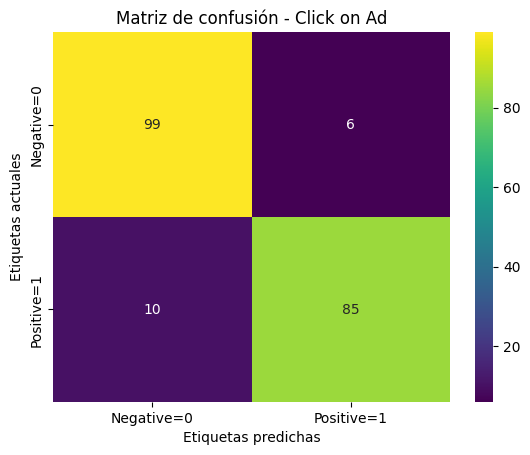

In [11]:
# Graficando la matriz de confusion
ax = plt.subplot()
sns.heatmap(con_matrix, annot=True, ax = ax, fmt='d', cmap = "viridis")

ax.set_xlabel('Etiquetas predichas')
ax.set_ylabel('Etiquetas actuales')
ax.set_title('Matriz de confusión - Click on Ad')
ax.xaxis.set_ticklabels(['Negative=0', 'Positive=1'])
ax.yaxis.set_ticklabels(['Negative=0', 'Positive=1']);
plt.show();

## Análisis de la matriz de confusión

De un total de 200 ejemplos, hay 84 valores positivos que fueron clasificados correctamente como positivos, 6 fueron clasificados incorrectamente (falsos positivos), 99 clasificados correctamente como negativos y 11 clasificados incorrectamente como falsos negativos.


In [12]:
from sklearn.metrics import classification_report
target_names = ['Clase 0','Clase 1']
print(classification_report(y_test, y_pred, labels=[0,1],target_names=target_names))

              precision    recall  f1-score   support

     Clase 0       0.91      0.94      0.93       105
     Clase 1       0.93      0.89      0.91        95

    accuracy                           0.92       200
   macro avg       0.92      0.92      0.92       200
weighted avg       0.92      0.92      0.92       200



Una de las medidas  de SOTA más importantes esla obtención de la precision, recall y la dedida de desempeño f1-score. La medida de **presicion** se define como todos los valores que se predijeron como positivos y el **recall**  se define como todos los valores que realmente son positivos.
\begin{align}
precision=\frac{TP}{TP+FP} \quad
\end{align}
\begin{align}
recall=\frac{TP}{TP+FN} \quad
\end{align}
Sobre  la matriz de confusión podemos obtener la precision, recall y el f1-score.

La precision de la Clase=1.
\begin{align}
precision=\frac{84}{84+6}=0.93333
\end{align}
El recall de la Clase=1
\begin{align}
recall=\frac{84}{84+11}=0.88
\end{align}
La precision de la Clase=0.
\begin{align}
precision=\frac{99}{99+11}=0.90
\end{align}
El recall de la Clase=0
\begin{align}
recall=\frac{99}{99+6}=0.942
\end{align}
La medida de desempeño de F1-score se define como la media armónica entre la precision y el recall:
\begin{align}
F1-score=2\cdot\frac{Precision \cdot Recall}{Precision+Recall}
\end{align}
El f1-score de la clase=1
\begin{align}
F1-score=2\cdot\frac{0.93 \cdot 0.88}{0.93+0.88} =0.9043
\end{align}
El f1-score de la clase=0
\begin{align}
F1-score=2\cdot\frac{0.90 \cdot 0.94}{0.90+0.94} =0.9195
\end{align}

# **CALCULO DEL ACCURACY**
Otra medida de desempeño importante es el accuracy que es mucho más global que el f1-score porque tiene en cuenta la información total de la matriz de confusión :
\begin{align}
accuracy=\frac{TP+TN}{TP+FP+FN+TN}
\end{align}
El accuracy para la matriz de confusión sería:
\begin{align}
accuracy=\frac{84+99}{84+6+11+99}= 0.915
\end{align}

# **VISUALIZACIÓN DE LA CURVA ROC**

Esta es una alternativa para dibujar la curva ROC

Probabilidad del verdadero positivo (TPR): [0.         0.01052632 0.68421053 0.68421053 0.74736842 0.74736842
 0.81052632 0.81052632 0.84210526 0.84210526 0.85263158 0.85263158
 0.92631579 0.92631579 0.93684211 0.93684211 0.94736842 0.94736842
 0.95789474 0.95789474 0.96842105 0.96842105 0.97894737 0.97894737
 0.98947368 0.98947368 1.         1.        ]
Probabilidad del falso positivo (FPR): [0.         0.         0.         0.00952381 0.00952381 0.01904762
 0.01904762 0.02857143 0.02857143 0.03809524 0.03809524 0.05714286
 0.05714286 0.06666667 0.06666667 0.07619048 0.07619048 0.0952381
 0.0952381  0.1047619  0.1047619  0.11428571 0.11428571 0.12380952
 0.12380952 0.2        0.2        1.        ]
Área bajo la curva (AUC): 0.9844611528822056


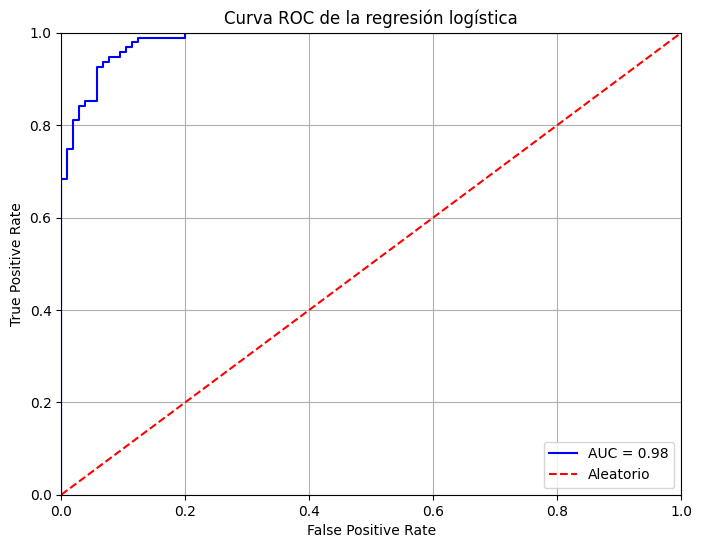

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Probabilidades predichas por el modelo
probs = log_model.predict_proba(X_test)
preds = probs[:, 1]  # probabilidad de la clase positiva

# Calcular curva ROC
fpr, tpr, threshold = roc_curve(y_test, preds)
roc_auc = auc(fpr, tpr)

# Mostrar métricas en consola
print('Probabilidad del verdadero positivo (TPR):', tpr)
print('Probabilidad del falso positivo (FPR):', fpr)
print('Área bajo la curva (AUC):', roc_auc)

# --- Gráfico ROC ---
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', label=f'AUC = {roc_auc:.2f}')
plt.plot([0, 1], [0, 1], 'r--', label='Aleatorio')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Curva ROC de la regresión logística')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


In [14]:
# AUC
print("The AUC is {auc}".format(auc=roc_auc))

The AUC is 0.9844611528822056


# **Máquinas de soporte vectorial**

Sea $x \in \mathbb{R}^{n}$ el epacio de características y $w \in \mathbb{R}^{n}$ los parámetros del sistema, es posible determinar un hiperplanp de decisión repreentando por $w \cdot x + b =0$. En la figura el hiperplano de la recta en $\mathbb{R}^{2}$ sería $w_{1}x_{1} + w_{2}x_{2} +b=0$

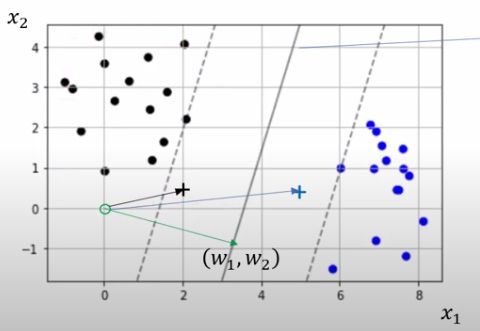



Las fronteras de decisión propuestas por Vaptnik aseguran que si las clases son separable siempre vamos a encontrar dos planos paralelos al hiperplano principal  y estos planos  pasan por los vectores de soporte al hiperplano, manteniendo la máxima margen para sostener los vectores de soporte.  Vaptnik define las fronteras de decisón  como los planos paralelos  para los vectores de soporte $x_{-}$ y $x_{+}$, son ellas,


\begin{align}
w\cdot x_{+} + b \geq 1 \quad \mbox{Clase 1}
\end{align}
\begin{align}
w\cdot x_{-} + b \leq -1 \quad \mbox{Clase -1}
\end{align}
La clasificación de Vaptnik se puede resumir en la siguiente ecuación:
\begin{align}
y_{i}(w\cdot x+b) \geq 1
\end{align}
\begin{Bmatrix}
y_{i}=1, x_{+}\\
y_{i}=-1, x_{-}
\end{Bmatrix}
Entonces para los vectores de sopote la ecuación es:
\begin{align}
y_{i}(w\cdot x+b)- 1 =0
\end{align}

# *Máximo margen de los vectores de soporte*

Para calcula la longitud del margen se miden las proyecciones de los vectores de soporte $(x_{-},x_{+})$ con respecto al vector $w=(w_{1},w_{2})$ donde $d_{-}$ es la proyección de $w$ con repecto al vector de soporte $x_{-}$ y $d_{+}$ es a proyección del vector $w$ con respecto al vector $x_{+}$. Por lo tanto la longiytud del margen es $d=d_{+} -d_{-}$, siendo  $d_{-}= \frac{x_{-} \cdot w}{\left \| w \right \|}$  y $d_{+}= \frac{x_{+} \cdot w}{\left \| w \right \|}$ entonces $d=d_{+} -d_{-}=\frac{1}{\left \|w \right \|}(x_{+}\cdot w - x_{-}\cdot w)$ ahora resolvemos: Como los vectores de soporte cumplen con la condción $y_{i}(w\cdot x +b)-1=0$ porque para todos los vectores cercanos al hiperplano $y_{i}(w\cdot x +b) \geq 1$ siendo $y_{i}=1$ para $x_{+}$ (vectores a la derecha) y  $y_{i}=-1$ para $x_{-}$ (vectores a la izquierda). Entonces retomamos el cálculo de la **longitud  máxima del margen** $d=d_{+} -d_{-}=\frac{1}{\left \|w \right \|}(x_{+}\cdot w - x_{-}\cdot w)$ para vectores a la derecha nos queda $(1)(w\cdot x_{+} +b)-1=0$, entonces $w\cdot x_{+}=1-b$ y

para los vectores de la izquierda  $(-1)(w\cdot x_{+} +b)-1=0$, entonces $w\cdot x_{-}=-1-b$.

Finalmente, reemplazando $d=d_{+} -d_{-}=\frac{1}{\left \|w \right \|}(x_{+}\cdot w - x_{-}\cdot w)=\frac{1}{\left \|w \right \|}(1-b+1+b)=\frac{2}{\left \|w \right \|}$.
![svm-3.png](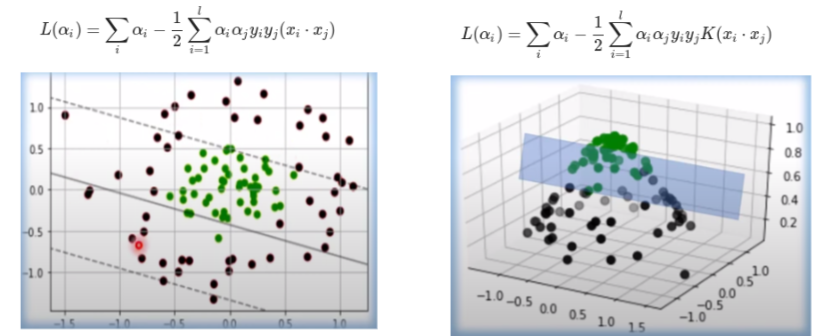jyFlMvWp1KatoVNrkJ3vjIw5JnPNZ2RkXAhRFKeWTW3K9f6P//iPPPjiAa7rJoXsj3HLj4iJUUoRx9HhctmQ9syoOAKRFhyVEEsQSDQk6Br4Pv5iBT8W0A+gtkd7Z4Od9TU6n/wKZRrkFytUbtxAyxfAsUGbsI6Oz0Uaw3pcGIVSiV9eTcz0pGD/yRNKpRLKdRLj68yzaqyns/OdkTHXZBbRjIyMC2FhoYxpWmxvb7O7s0ulWuGv/uqv+Pzz+3zlq1/hk48/QUrJRx9+xIOHD/m93/tdCoXClJVNExpSSqRMh7KRxxhAKcRx01xeZkbq6tysuiNrs0r/mnCrj46pTEWiZUD+Jv6t6/hxDIMB4UGN+s42n/7sfaL+AN/18YsFFm6swuICeF4iNGOVWF6lSLz3o6z3cbZWPKrsD6GAfo/OwT43v/Y2xByxhmaW0IyM14f/H2jqjvVdBWPZAAAAAElFTkSuQmCC)

# **La idea es la de maximizar la longitud del margen $d=\frac{2}{\left \|w \right \|}$**

El probema de encontrar un hiperplano que separe un conjunto de clases de otro se vuelve un problema de optimización de la minimización de la **función objetivo** $f(w)=\frac{1}{2}w^{T}w$, esta función objetivo se define en términos de la mimnimización  de $d=\frac{2}{\left \|w \right \|}$ además de considerar la restricción  para  para cada vector de soporte $g(w,b)=y_{i}(w\cdot x_{\pm} +b)-1=0$, usando lagrangiano se obtiene una función mucho más inclusiva y parametrizable para clases linealmente separables, basada en restricciones:

\begin{align}
L(w,b,\alpha)=f(w) +\alpha g(w,b)
\end{align}
Para encontrar los coeficientes de Lagrange $\alpha_{i}$ hay que derivar parcialmente $w,b$ y $\alpha$ e igualarlas a cero para minimizar la suma de la función objetivo y la restricción de los vectores de soporte.
\begin{align}
L(w,b,\alpha_{i})=\frac{1}{2}w^{T}w-\sum_{i=1}^{l} \alpha_{i}[y_{i}(w\cdot x +b)-1]
\end{align}
Donde $l$ es el número de vectores de soporte, con el fin de obtener el mínimo de la función $L$ se aplican derivadas parciales y se iguala a cero obteniendo así una ecuación más sencilla en función de los coeficientes de Lagrange  $\alpha_{i}$ y del producto punto entre $x_{i} \cdot x_{j}$:

\begin{align}
L(\alpha_{i})=\sum_{i}\alpha_{i}-\frac{1}{2}\sum_{i=1}^{l} \alpha_{i}\alpha_{j}y_{i}y_{j}(x_{i}\cdot x_{j})
\end{align}

En el caso de que las clases no sean linealmente separables se realiza una transformación al producto punto  $(x_{i}\cdot x_{j})$  y se aplican kernels $K(x_{i}\cdot x_{j})$ aumentando la dimensionalidad del espacio de entrada de $(x_{i}\cdot x_{j})$ convirtiendo un sistema de clases no separables a separables, quedando así la nueva ecuación:
\begin{align}
L(\alpha_{i})=\sum_{i}\alpha_{i}-\frac{1}{2}\sum_{i=1}^{l} \alpha_{i}\alpha_{j}y_{i}y_{j}K(x_{i}\cdot x_{j})
\end{align}


### **Creando un modelo de clasificación lineal usando MÁQINAS DE SOPORTE VECTORIAL:**

9. Utilizando los mismos datos separados anteriormente, crear un modelo de clasificación lineal. Obtener la matriz de confusión para este modelo, graficarla, obtener la precisión y el recall, f1-score, accuracy y ROC.
    
Las SVM o máquinas de soporte vectorial resueven el problema de la clasificación más robusta para datos separables y no separables.